# Chạy trên tập feature A 

## feature A (RFM)

## Params

In [2]:
RANDOM_STATE = 42
INIT = "k-means++"
N_INIT = 10
MAX_ITER = 300
TOL = 1e-4

## import thư viện

In [ ]:
import joblib
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [4]:
path = "data/customer_features.csv"
df = pd.read_csv(path, dtype={"CustomerID": "string"})

FEATURE_A = ["Recency", "Frequency", "Monetary"]
X = df[FEATURE_A].copy()
X.head()

,Recency,Frequency,Monetary
0,3,7,4310.00
1,76,4,1437.24
2,19,1,1457.55
3,311,1,294.40
4,37,7,1385.74


## kiểm tra lại missing RFM

In [5]:
cols = X.columns.to_list()
for col in cols:
    missng_sum=X[col].isnull().sum()
    missing_per=len(X[col])
    if(X[col].isnull().sum()>0):
        print(f"{col}:{(missng_sum/missing_per)*100}")

In [6]:
model=KMeans()

* Dựa trên kết quả đánh giá thuật toán K-Means với số cụm k thay đổi từ 2 đến 10, có thể rút ra một số nhận xét như sau:

* Silhouette Score: Đạt giá trị cao nhất tại k = 2 (0.9852), sau đó giảm dần khi số cụm tăng. Đặc biệt, các giá trị k từ 2 đến 4 đều có Silhouette Score trên 0.95, cho thấy khả năng phân tách cụm rất tốt.

* Davies-Bouldin Index (DBI): Đạt giá trị thấp nhất tại k = 3 (0.3523), cho thấy mức độ phân tách và độ chặt chẽ của các cụm tương đối tốt.

* Calinski-Harabasz Index (CHI): Có  hướng tăng 

## Scaling lại dữ liệu

* Do Monetary có giá trị lớn hơn rất nhiều so với Recency và Frequency nên Monetary gần như quyết định toàn bộ khoảng cách giữa các khách hàng.
* Hậu quả là K-Means có thể phân cụm chủ yếu dựa trên số tiền chi tiêu, trong khi Recency và Frequency ít ảnh hưởng đến kết quả.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
results = []
for k in range(2, min(10, len(X) - 1) + 1):
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(X_scaled)
    results.append({
        'k': k,
        'Silhouette': silhouette_score(X, labels),
        'DBI': davies_bouldin_score(X, labels),
        'CHI': calinski_harabasz_score(X, labels),
        'Inertia': model.inertia_
    })
metrics = pd.DataFrame(results)
display(metrics.round(4))


,k,Silhouette,DBI,CHI,Inertia
0,2,0.9698,0.6607,4439.5665,8950.5986
1,3,-0.1082,1.2393,2261.5617,5381.8486
2,4,-0.0427,1.1467,2557.7832,4022.6720
3,5,-0.0219,1.0008,5536.4180,3002.7288
4,6,-0.0044,1.7168,5000.4299,2349.2241
5,7,-0.1414,2.0153,4261.1649,1895.6172
6,8,-0.0695,2.3837,3833.4402,1577.1689
7,9,-0.0614,2.8530,3989.9848,1335.8447
8,10,-0.1127,3.3270,3561.9619,1179.8267


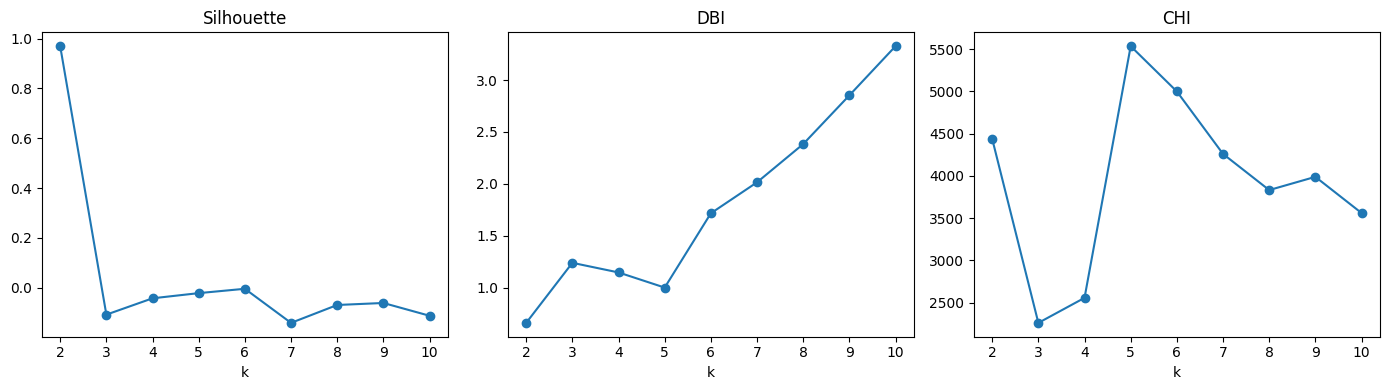

K được đề xuất theo Silhouette: 2


In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['Silhouette','DBI','CHI']):
    ax.plot(metrics['k'], metrics[col], marker='o')
    ax.set_xlabel('k')
    ax.set_title(col)
plt.tight_layout()
plt.show()

best_k = int(metrics.loc[metrics['Silhouette'].idxmax(), 'k'])
fig.savefig("figures/kmeans_metrics.png", dpi=300, bbox_inches="tight")
print('K được đề xuất theo Silhouette:', best_k)

* Kết quả cho thấy Silhouette Score đạt giá trị cao nhất tại k = 2 (khoảng 0.97), sau đó giảm mạnh và chủ yếu nhận giá trị âm khi số cụm tăng. Điều này cho thấy dữ liệu có khả năng phân tách tốt thành hai cụm theo chỉ số Silhouette, trong khi việc chia thành nhiều cụm hơn làm giảm chất lượng phân tách.

* Đối với Davies-Bouldin Index, giá trị thấp nhất cũng xuất hiện tại k = 2 (khoảng 0.67), đồng thời có xu hướng tăng khi số cụm lớn hơn. Kết quả này cho thấy phương án hai cụm có mức độ phân tách và độ chặt chẽ tương đối tốt.

* Trong khi đó, Calinski-Harabasz Index đạt giá trị cao nhất tại k = 5 (khoảng 5530), cho thấy sự khác biệt trong kết quả đánh giá giữa các chỉ số.

## Train model với thông số mặc định và best K

In [10]:
best_model = KMeans(n_clusters=best_k, n_init=20, random_state=42)
cluster_labels = best_model.fit_predict(X)
df["Cluster"] = cluster_labels
display(df.groupby("Cluster").size().rename("Số khách"))

Cluster
0    4320
1       7
Name: Số khách, dtype: int64

In [11]:
model = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    init=INIT,
    n_init=N_INIT,
    max_iter=MAX_ITER,
    tol=TOL,
)
labels = model.fit_predict(X_scaled)
result = df[["CustomerID"] + FEATURE_A].copy()
result["cluster"] = labels
print("Số lượng theo cụm:")
print(result["cluster"].value_counts().sort_index())
display(result.head())

Số lượng theo cụm:
cluster
0    4303
1      24
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,0
1,12348,76,4,1437.24,0
2,12349,19,1,1457.55,0
3,12350,311,1,294.40,0
4,12352,37,7,1385.74,0


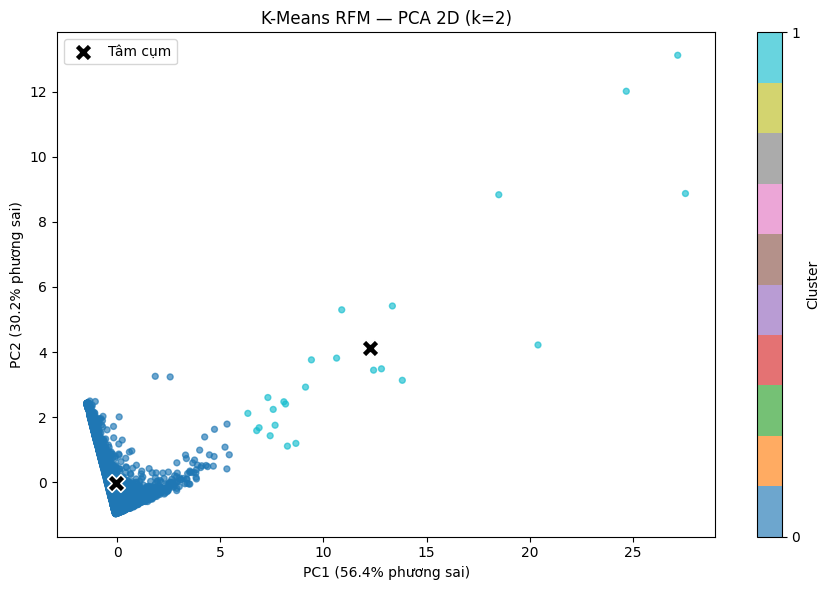

In [12]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
centers_2d = pca.transform(model.cluster_centers_)

fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(coords[:, 0], coords[:, 1], c=labels,
                     cmap="tab10", s=18, alpha=0.65, rasterized=True)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black",
           marker="X", s=160, edgecolors="white", linewidths=1.2,
           label="Tâm cụm")
ax.set_title(f"K-Means RFM — PCA 2D (k={best_k})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} phương sai)")
ax.legend(loc="best")
fig.colorbar(scatter, ax=ax, label="Cluster", ticks=sorted(np.unique(labels)))
fig.tight_layout()
fig.savefig("figures/kmeans_clusters_pca.png", dpi=300, bbox_inches="tight")
plt.show()


In [13]:
cluster_count = pd.Series(labels).value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "Số khách hàng": cluster_count,
    "Tỷ lệ (%)": (cluster_count / len(labels) * 100).round(2)
})

display(cluster_summary)

,Số khách hàng,Tỷ lệ (%)
0,4303,99.45
1,24,0.55


In [14]:
df_result = df.copy()
df_result["Cluster"] = labels

display(
    df_result.groupby("Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].median()
)

,Recency,Frequency,Monetary
Cluster,,,
0,52.0,2.0,655.58
1,3.5,55.5,58396.28


## số lượng khách hàng theo từng cụm

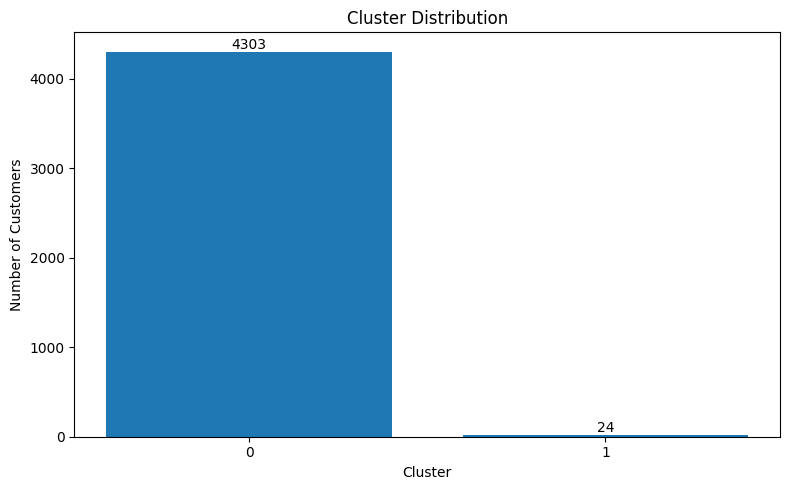

In [16]:
cluster_counts = result["cluster"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(cluster_counts.index, cluster_counts.values)

ax.set_title("Cluster Distribution")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Customers")
ax.set_xticks(cluster_counts.index)

for i, count in enumerate(cluster_counts):
    ax.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
fig.savefig("figures/kmeans_cluster_distribution.png", dpi=300)
plt.show()

## RFM theo từng cụm

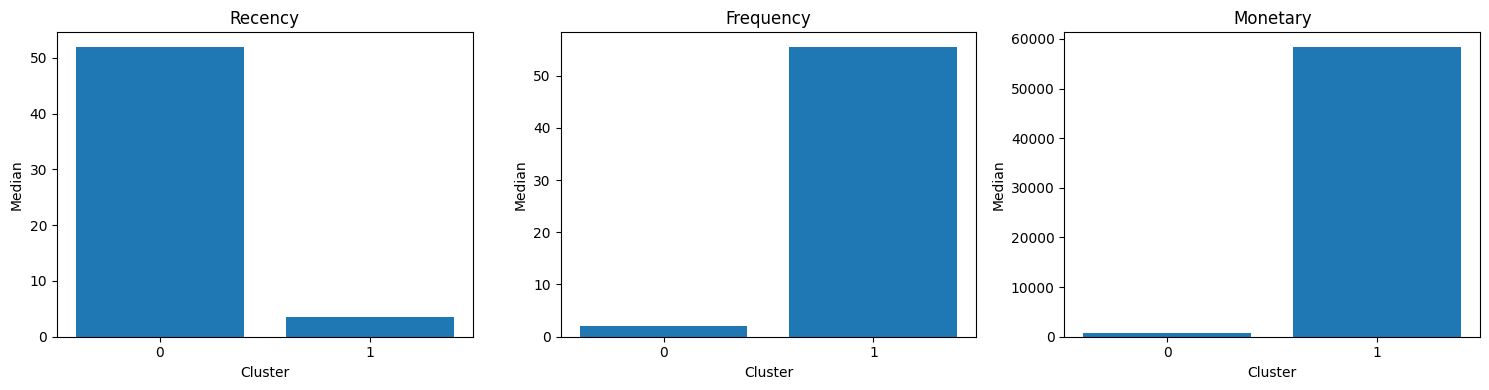

In [17]:
rfm = result.groupby("cluster")[FEATURE_A].median()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, FEATURE_A):
    ax.bar(rfm.index, rfm[feature])
    ax.set_title(feature)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Median")
    ax.set_xticks(rfm.index)

plt.tight_layout()
fig.savefig("figures/kmeans_rfm_comparison.png", dpi=300)
plt.show()

* Cụm 0 – Khách hàng phổ thông: Gồm 4.303 khách hàng, chiếm 99,45% tổng số khách hàng. Nhóm này có trung vị Recency là 52 ngày, Frequency là 2 lần và Monetary là 655,58. Điều này cho thấy phần lớn khách hàng có tần suất mua hàng và mức chi tiêu tương đối thấp so với nhóm còn lại.

* Cụm 1 – Khách hàng VIP: Gồm 24 khách hàng, chiếm 0,55% tổng số khách hàng. Nhóm này có trung vị Recency là 3,5 ngày, Frequency là 55,5 lần và Monetary là 58.396,28. Các đặc trưng này cho thấy đây là nhóm khách hàng có hoạt động mua sắm thường xuyên, thời gian mua gần nhất ngắn và giá trị chi tiêu vượt trội.

* Kết quả phân cụm cho thấy mô hình K-Means đã nhận diện được nhóm khách hàng có giá trị đặc biệt cao. Tuy nhiên, sự chênh lệch lớn về số lượng khách hàng giữa hai cụm cho thấy mô hình chủ yếu phân biệt nhóm khách hàng VIP với phần lớn khách hàng phổ thông, thay vì tạo ra nhiều phân khúc khách hàng có đặc điểm đa dạng.

# lưu tham số mô hình 

In [15]:
import json
import joblib

# 1. Điểm mô hình
print("Silhouette:", silhouette_score(X_scaled, labels))
print("DBI:", davies_bouldin_score(X_scaled, labels))
print("CHI:", calinski_harabasz_score(X_scaled, labels))
print("Inertia:", model.inertia_)

# 2. Lưu tham số
with open("kmeans_params.json", "w") as f:
    json.dump(model.get_params(), f, indent=4)

# 3. Lưu model
joblib.dump(model, "kmeans_model.pkl")

Silhouette: 0.8993587821096044
DBI: 0.7274616155492135
CHI: 1947.5218339357023
Inertia: 8950.598576836375


['kmeans_model.pkl']